In [1]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from utils import fetch_df

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
%matplotlib inline

In [2]:
query_ret = """
SELECT
    cohort_date,
    maxIf(retained_users, day_n = 0) AS day_0,
    maxIf(retained_users, day_n = 1) AS day_1,
    maxIf(retained_users, day_n = 7) AS day_7,
    maxIf(retained_users, day_n = 14) AS day_14,
    maxIf(retained_users, day_n = 30) AS day_30
FROM neobank_marts.dm_retention
GROUP BY cohort_date
ORDER BY cohort_date
"""
df_ret = fetch_df(query_ret)

# Считаем проценты (Retention Rate)
for col in ["day_1", "day_7", "day_14", "day_30"]:
    df_ret[col + "_pct"] = (df_ret[col] / df_ret["day_0"]) * 100

# Оставляем только проценты для тепловой карты
df_heatmap = df_ret[["cohort_date", "day_1_pct", "day_7_pct", "day_14_pct", "day_30_pct"]].set_index("cohort_date")
df_heatmap.columns = ["Day 1", "Day 7", "Day 14", "Day 30"]
df_heatmap.head()

,Day 1,Day 7,Day 14,Day 30
cohort_date,,,,
2024-01-04,0.000000,0.000000,0.000000,0.000000
2024-01-05,50.000000,0.000000,0.000000,0.000000
2024-01-06,0.000000,0.000000,0.000000,0.000000
2024-01-07,71.428571,0.000000,14.285714,14.285714
2024-01-08,50.000000,16.666667,16.666667,0.000000


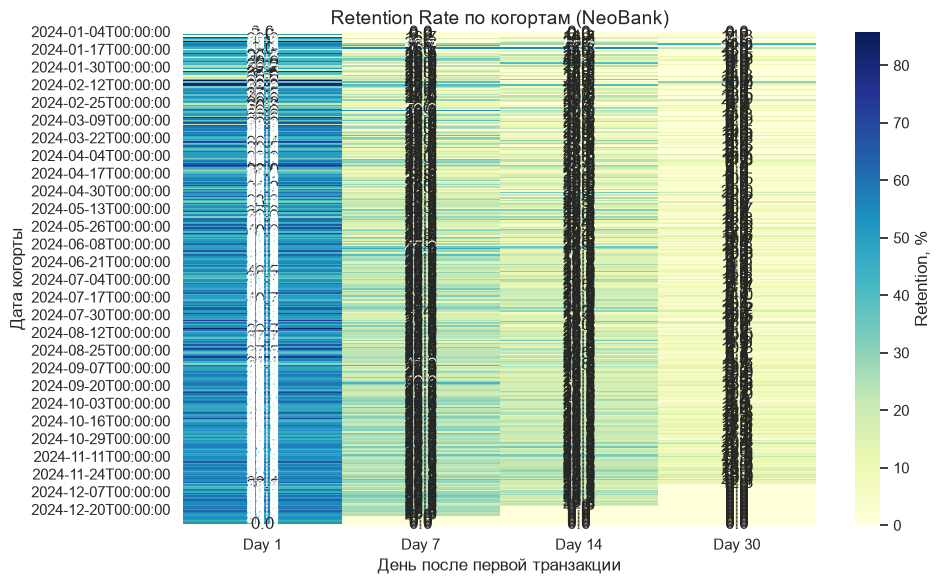

In [3]:
plt.figure(figsize=(10, 6))
sns.heatmap(df_heatmap, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Retention, %'})
plt.title("Retention Rate по когортам (NeoBank)", fontsize=14)
plt.xlabel("День после первой транзакции", fontsize=12)
plt.ylabel("Дата когорты", fontsize=12)
plt.tight_layout()
plt.show()

In [4]:
query_ab = """
SELECT
    experiment_id,
    group,
    users,
    avg_tx_per_user,
    arpu
FROM neobank_marts.dm_ab_results
ORDER BY experiment_id, group
"""
df_ab = fetch_df(query_ab)
df_ab

,experiment_id,group,users,avg_tx_per_user,arpu
0,1,control,2536,5.126183,252802.692675
1,1,treatment,2442,5.546683,260675.024233
2,2,control,7662,5.596450,268226.616989
3,2,treatment,7496,5.927561,278909.117920
4,3,control,12349,6.661592,286556.527092
5,3,treatment,12206,6.083647,265196.455420
6,4,control,18875,6.323974,259816.869550
7,4,treatment,17294,6.535793,261185.156538


In [5]:
# В реальной жизни мы бы брали сырые данные по каждому пользователю.
# Здесь мы возьмем агрегированные средние и применим t-test для демонстрации.
# Для честного теста нам нужны данные из stg_ab_assignments (сделаем это на следующем шаге, если захотим).
# А пока просто визуализируем то, что есть в витрине.

pivot_ab = df_ab.pivot(index="experiment_id", columns="group", values="arpu")
pivot_ab["diff"] = pivot_ab["treatment"] - pivot_ab["control"]
pivot_ab["lift_pct"] = (pivot_ab["treatment"] / pivot_ab["control"] - 1) * 100

pivot_ab.round(2)

group,control,treatment,diff,lift_pct
experiment_id,,,,
1,252802.69,260675.02,7872.33,3.11
2,268226.62,278909.12,10682.50,3.98
3,286556.53,265196.46,-21360.07,-7.45
4,259816.87,261185.16,1368.29,0.53
